In [6]:
import gc                                # garbage collector, used to free RAM
import numpy as np                       # NumPy: numerical arrays
import pandas as pd                      # pandas: tables
import scanpy as sc                      # Scanpy: single-cell analysis
import matplotlib.pyplot as plt          # matplotlib: plotting
from pathlib import Path                 # Path: file and folder paths

project_dir = Path.cwd().parent          # notebook lives in Notebook/, so parent = project root
proc_dir   = project_dir / "data" / "processed"
fig_dir    = project_dir / "Figure"
result_dir = project_dir / "Result"

adata = sc.read_h5ad(proc_dir / "merged_annotated_v2.h5ad")      # log-normalised data, counts in layers["counts"]
# D7 cells that are not flagged, and excluding the single D7 cell that was assigned to the D14/D21 epiblast cluster
keep = ((adata.obs["sample"] == "D7") & (~adata.obs["exclude_default"])
        & (adata.obs["cell_state_v2"] != "Epiblast-like (bEPI, D14/D21)"))
sub = adata[keep].copy()                                          # independent copy of the D7 cells
sub.obs["cell_state_v2"] = sub.obs["cell_state_v2"].cat.remove_unused_categories()   # drop labels that no longer occur (PAGA needs this)
print(sub.shape)
print(sub.obs["cell_state_v2"].value_counts())
del adata                                                         # the full object is not needed any more
gc.collect()

(4451, 36601)
cell_state_v2
Epiblast-like (bEPI, D7)         1890
TE-like (bTE)                    1878
Epiblast-like (TE-primed, D7)     465
Primitive endoderm-like (bPE)     116
Polar TE-like (bPolarTE)          102
Name: count, dtype: int64


30900

In [7]:
# Highly variable genes within D7 only (log-normalised data)
sc.pp.highly_variable_genes(sub, n_top_genes=2000, flavor="seurat")
hv = sub[:, sub.var["highly_variable"]].copy()                  # keep only these genes for the embedding
sc.pp.scale(hv, max_value=10)                                   # mean 0 / variance 1 per gene; clip at 10 SD
sc.tl.pca(hv, n_comps=30, svd_solver="arpack", random_state=0)
sc.pp.neighbors(hv, n_neighbors=15, n_pcs=15, random_state=0)   # 15 PCs, as in the original study for D7
sc.tl.umap(hv, random_state=0)

C:\Users\ADMIN\miniconda3\envs\blastoid\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


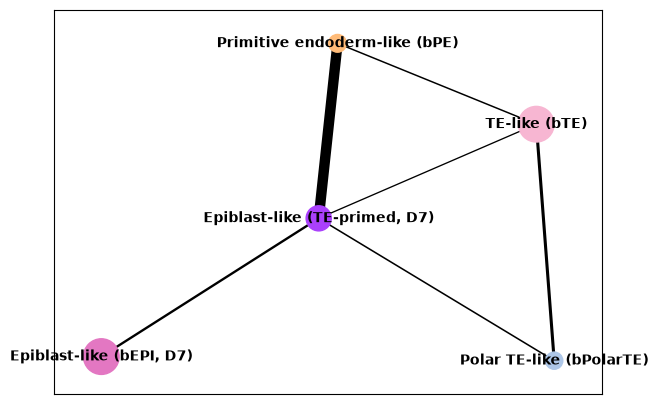

In [8]:
sc.tl.paga(hv, groups="cell_state_v2")                          # connectivity between the 5 cell states
sc.pl.paga(hv, threshold=0.05, node_size_scale=2, show=False)   # edges weaker than 0.05 are hidden
plt.gcf().savefig(fig_dir / "D7_paga.png", dpi=200, bbox_inches="tight")
plt.show()

root cell: TTCTCTCTCCTATGGA-1_D7
cell_state_v2
Epiblast-like (bEPI, D7)         0.064
Epiblast-like (TE-primed, D7)    0.219
Primitive endoderm-like (bPE)    0.367
TE-like (bTE)                    0.533
Polar TE-like (bPolarTE)         0.636
Name: dpt_pseudotime, dtype: float32


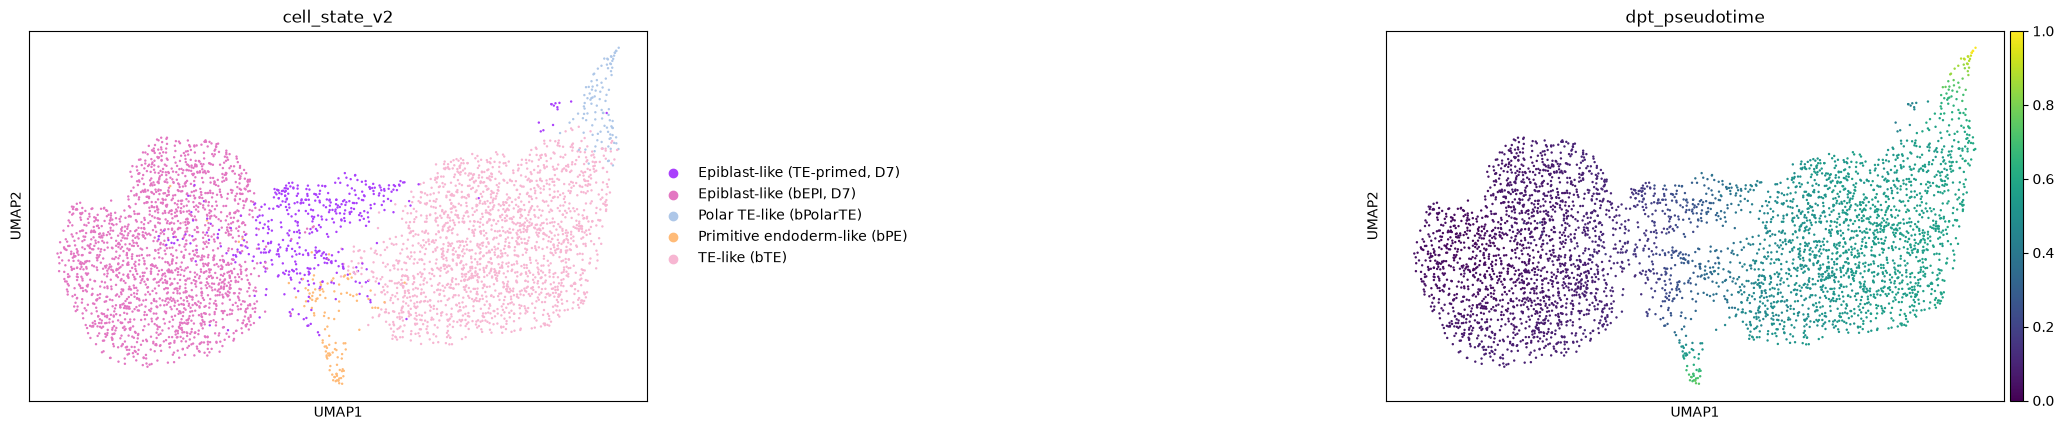

In [9]:
# Score every cell by the mean expression of naive-pluripotency genes (uses the full log-normalised data in "sub")
naive = [g for g in ["DNMT3L", "KHDC1L", "SUSD2", "TFCP2L1"] if g in sub.var_names]
sc.tl.score_genes(sub, gene_list=naive, score_name="naive_score")
hv.obs["naive_score"] = sub.obs["naive_score"].to_numpy()       # copy the score to the embedding object (same cell order)

# Root = epiblast-like (D7) cell with the highest naive score
epi = hv.obs[hv.obs["cell_state_v2"] == "Epiblast-like (bEPI, D7)"]
root_cell = epi["naive_score"].idxmax()
hv.uns["iroot"] = int(np.flatnonzero(hv.obs_names == root_cell)[0])   # Scanpy wants the integer position of the root cell
print("root cell:", root_cell)

sc.tl.diffmap(hv)                          # diffusion map: smooth low-dimensional coordinates of the cell graph
sc.tl.dpt(hv, n_dcs=10)                    # diffusion pseudotime: graph distance from the root, using 10 diffusion components
sub.obs["dpt_pseudotime"] = hv.obs["dpt_pseudotime"].to_numpy()

# Which cell states come early or late? Median pseudotime per cell state
print(hv.obs.groupby("cell_state_v2", observed=True)["dpt_pseudotime"].median().sort_values().round(3))

sc.pl.umap(hv, color=["cell_state_v2", "dpt_pseudotime"], ncols=2, wspace=1.0, size=12, show=False)
plt.gcf().savefig(fig_dir / "D7_pseudotime_umap.png", dpi=200, bbox_inches="tight")
plt.show()

hv.obs[["cell_state_v2", "naive_score", "dpt_pseudotime"]].to_csv(result_dir / "D7_pseudotime.csv")

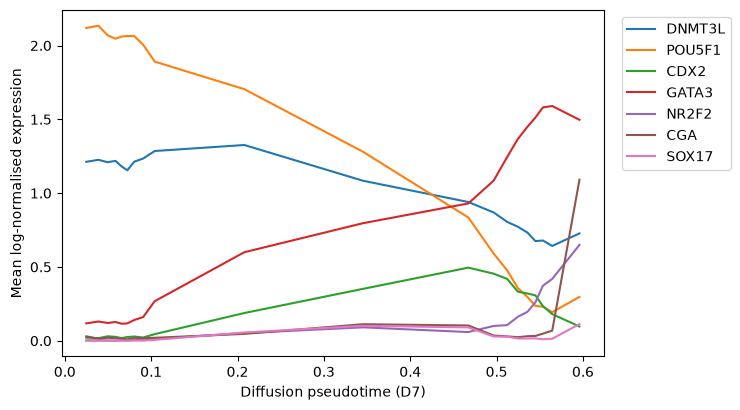

In [10]:
genes = [g for g in ["DNMT3L", "POU5F1", "CDX2", "GATA3", "NR2F2", "CGA", "SOX17"] if g in sub.var_names]
X = sub[:, genes].X                                              # log-normalised expression of these genes
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)      # sparse -> dense (7 genes only, small)
df = pd.DataFrame(X, columns=genes, index=sub.obs_names)

# qcut makes 20 intervals that each contain about the same NUMBER of cells (equal-width bins gave tiny groups at the end)
bins = pd.qcut(sub.obs["dpt_pseudotime"], q=20, duplicates="drop")
trend = df.groupby(bins, observed=True)[genes].mean()                         # mean expression per interval
x = sub.obs.groupby(bins, observed=True)["dpt_pseudotime"].median()           # x position = median pseudotime of the interval

plt.figure(figsize=(7, 4.5))
for g in genes:
    plt.plot(x.to_numpy(), trend[g].to_numpy(), label=g)
plt.xlabel("Diffusion pseudotime (D7)")
plt.ylabel("Mean log-normalised expression")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig(fig_dir / "D7_gene_trends.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
from scipy.stats import spearmanr              # rank correlation between two pseudotime vectors

def run_dpt(n_pcs, root_cell):
    """Recompute the neighbour graph and diffusion pseudotime with a given number of PCs and root cell."""
    h = hv.copy()                              # work on a copy so the original result stays untouched
    sc.pp.neighbors(h, n_neighbors=15, n_pcs=n_pcs, random_state=0)
    h.uns["iroot"] = int(np.flatnonzero(h.obs_names == root_cell)[0])
    sc.tl.diffmap(h)
    sc.tl.dpt(h, n_dcs=10)
    return h.obs["dpt_pseudotime"]

epi = hv.obs[hv.obs["cell_state_v2"] == "Epiblast-like (bEPI, D7)"]
roots = epi["naive_score"].nlargest(5).index   # the five epiblast cells with the highest naive score
variants = {                                   # alternative choices to compare with the original (15 PCs, best root)
    "10 PCs":        run_dpt(10, roots[0]),
    "20 PCs":        run_dpt(20, roots[0]),
    "2nd-best root": run_dpt(15, roots[1]),
    "5th-best root": run_dpt(15, roots[4]),
}
orig = hv.obs["dpt_pseudotime"]
for name, pt in variants.items():
    rho = spearmanr(orig, pt).correlation      # 1.0 = identical cell ordering
    order = pt.groupby(hv.obs["cell_state_v2"], observed=True).median().sort_values().round(2)
    print(f"{name}: Spearman rho vs original = {rho:.3f}")
    print("   state order:", " < ".join(f"{k.split(' (')[0]} {v}" for k, v in order.items()))

10 PCs: Spearman rho vs original = 0.989
   state order: Epiblast-like 0.09000000357627869 < Epiblast-like 0.20000000298023224 < Primitive endoderm-like 0.33000001311302185 < TE-like 0.49000000953674316 < Polar TE-like 0.550000011920929
20 PCs: Spearman rho vs original = 0.985
   state order: Epiblast-like 0.09000000357627869 < Epiblast-like 0.27000001072883606 < Primitive endoderm-like 0.4300000071525574 < TE-like 0.6100000143051147 < Polar TE-like 0.7200000286102295
2nd-best root: Spearman rho vs original = 0.999
   state order: Epiblast-like 0.07000000029802322 < Epiblast-like 0.2199999988079071 < Primitive endoderm-like 0.36000001430511475 < TE-like 0.5199999809265137 < Polar TE-like 0.6299999952316284
5th-best root: Spearman rho vs original = 0.900
   state order: Epiblast-like 0.09000000357627869 < Epiblast-like 0.14000000059604645 < Primitive endoderm-like 0.30000001192092896 < TE-like 0.4699999988079071 < Polar TE-like 0.5899999737739563


In [12]:
def embed_subset(sub, n_hvg=2000, n_pcs=15):
    """Highly variable genes -> scale -> PCA -> neighbours -> UMAP, computed on a subset of cells only."""
    sc.pp.highly_variable_genes(sub, n_top_genes=n_hvg, flavor="seurat")   # variable genes within this subset
    hv = sub[:, sub.var["highly_variable"]].copy()                          # small copy with only those genes
    sc.pp.scale(hv, max_value=10)                                           # mean 0 / variance 1 per gene; clip at 10 SD
    sc.tl.pca(hv, n_comps=30, svd_solver="arpack", random_state=0)
    sc.pp.neighbors(hv, n_neighbors=15, n_pcs=n_pcs, random_state=0)        # 15 PCs, the number used in the original study
    sc.tl.umap(hv, random_state=0)
    return hv

def dpt_from_root(hv, root_cell, n_pcs=15):
    """Diffusion pseudotime from a chosen root cell (works on a copy, so hv is not modified)."""
    h = hv.copy()
    sc.pp.neighbors(h, n_neighbors=15, n_pcs=n_pcs, random_state=0)
    h.uns["iroot"] = int(np.flatnonzero(h.obs_names == root_cell)[0])       # Scanpy needs the integer position of the root
    sc.tl.diffmap(h)
    sc.tl.dpt(h, n_dcs=10)
    return h.obs["dpt_pseudotime"]

def robustness(hv, root_candidates, label_col="cell_state_v2"):
    """Recompute pseudotime with other PC numbers and root cells; report rank correlation and state order."""
    from scipy.stats import spearmanr
    orig = hv.obs["dpt_pseudotime"]
    variants = {"10 PCs": dpt_from_root(hv, root_candidates[0], 10),
                "20 PCs": dpt_from_root(hv, root_candidates[0], 20),
                "2nd-best root": dpt_from_root(hv, root_candidates[1]),
                "5th-best root": dpt_from_root(hv, root_candidates[4])}
    for name, pt in variants.items():
        rho = spearmanr(orig, pt).correlation                              # 1.0 = identical ordering of cells
        order = pt.groupby(hv.obs[label_col], observed=True).median().sort_values()
        print(f"{name}: Spearman rho = {rho:.3f} | " + " < ".join(f"{k} {v:.2f}" for k, v in order.items()))

In [13]:
adata = sc.read_h5ad(proc_dir / "merged_annotated_v2.h5ad")
troph_states = ["CTB-like (bCTB)", "EVT-like (bEVT)", "Primitive syncytium-like (bPrSyn)", "ST-like (bSTB)"]
keep = ((adata.obs["sample"] == "D14") & (~adata.obs["exclude_default"])
        & adata.obs["cell_state_v2"].isin(troph_states))                    # D14 trophoblast cells that are not flagged
sub14 = adata[keep].copy()
sub14.obs["cell_state_v2"] = sub14.obs["cell_state_v2"].cat.remove_unused_categories()   # drop unused labels (PAGA needs this)
print(sub14.shape)
print(sub14.obs["cell_state_v2"].value_counts())
del adata
gc.collect()

(2799, 36601)
cell_state_v2
ST-like (bSTB)                       894
EVT-like (bEVT)                      785
CTB-like (bCTB)                      688
Primitive syncytium-like (bPrSyn)    432
Name: count, dtype: int64


6606

In [14]:
adata = sc.read_h5ad(proc_dir / "merged_annotated_v2.h5ad")
troph_states = ["CTB-like (bCTB)", "EVT-like (bEVT)", "Primitive syncytium-like (bPrSyn)", "ST-like (bSTB)"]
keep = ((adata.obs["sample"] == "D14") & (~adata.obs["exclude_default"])
        & adata.obs["cell_state_v2"].isin(troph_states))                    # D14 trophoblast cells that are not flagged
sub14 = adata[keep].copy()
sub14.obs["cell_state_v2"] = sub14.obs["cell_state_v2"].cat.remove_unused_categories()   # drop unused labels (PAGA needs this)
print(sub14.shape)
print(sub14.obs["cell_state_v2"].value_counts())
del adata
gc.collect()

(2799, 36601)
cell_state_v2
ST-like (bSTB)                       894
EVT-like (bEVT)                      785
CTB-like (bCTB)                      688
Primitive syncytium-like (bPrSyn)    432
Name: count, dtype: int64


747

C:\Users\ADMIN\miniconda3\envs\blastoid\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


root cell: TCAATCTGTGCCGGTT-1_D14
cell_state_v2
CTB-like (bCTB)                      0.161
EVT-like (bEVT)                      0.470
Primitive syncytium-like (bPrSyn)    0.640
ST-like (bSTB)                       0.773
Name: dpt_pseudotime, dtype: float32


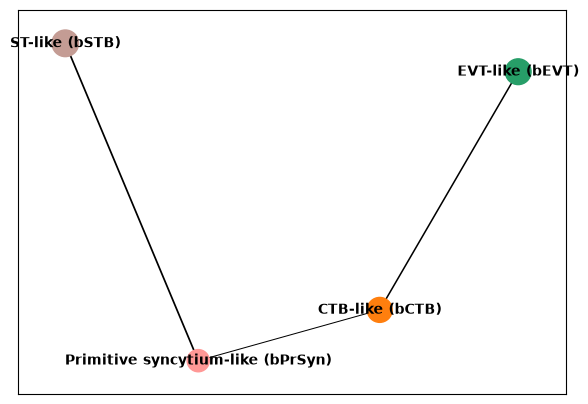

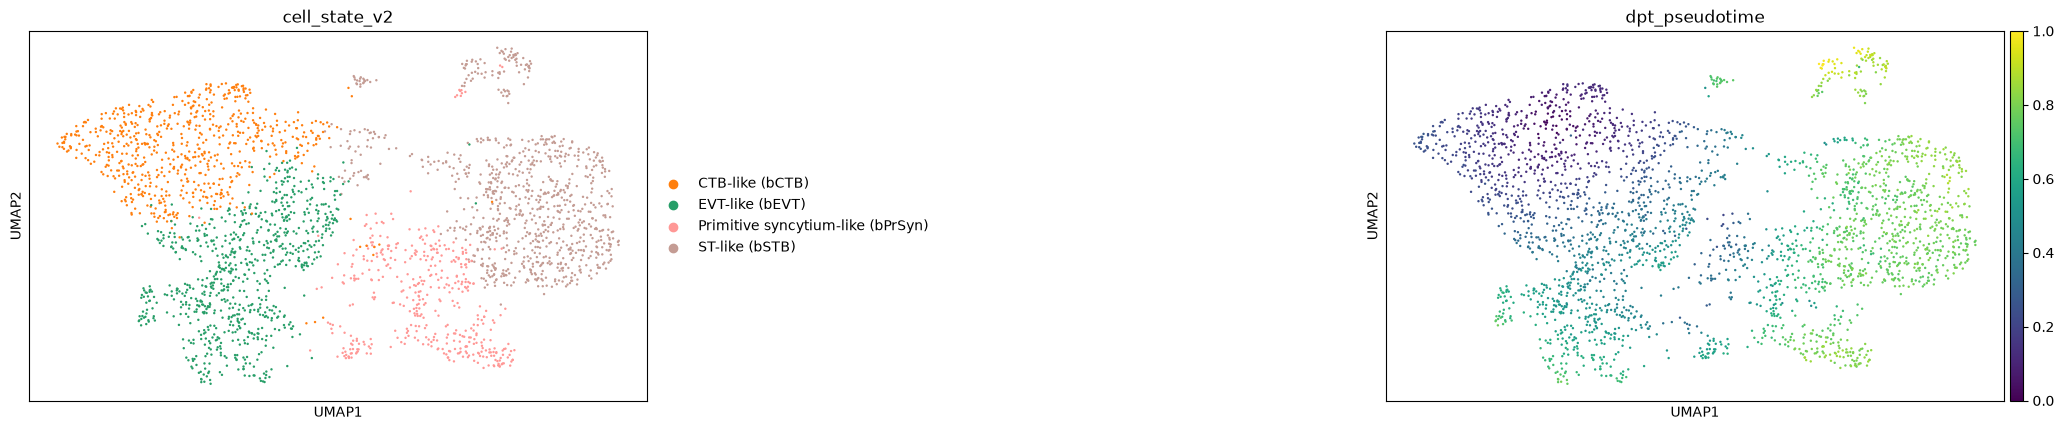

In [15]:
hv14 = embed_subset(sub14)

# Root: CTB-like cell with the highest mean expression of CTB marker genes
ctb_genes = [g for g in ["VGLL1", "ITGA6", "YAP1", "TP63"] if g in sub14.var_names]
sc.tl.score_genes(sub14, gene_list=ctb_genes, score_name="ctb_score")
hv14.obs["ctb_score"] = sub14.obs["ctb_score"].to_numpy()                   # same cell order in both objects
ctb = hv14.obs[hv14.obs["cell_state_v2"] == "CTB-like (bCTB)"]
root14 = ctb["ctb_score"].idxmax()
hv14.uns["iroot"] = int(np.flatnonzero(hv14.obs_names == root14)[0])
print("root cell:", root14)

sc.tl.diffmap(hv14)
sc.tl.dpt(hv14, n_dcs=10)
print(hv14.obs.groupby("cell_state_v2", observed=True)["dpt_pseudotime"].median().sort_values().round(3))

# PAGA: which states connect to which
sc.tl.paga(hv14, groups="cell_state_v2")
sc.pl.paga(hv14, threshold=0.05, node_size_scale=2, show=False)
plt.gcf().savefig(fig_dir / "D14_troph_paga.png", dpi=200, bbox_inches="tight")
plt.show()

sc.pl.umap(hv14, color=["cell_state_v2", "dpt_pseudotime"], ncols=2, wspace=1.0, size=12, show=False)
plt.gcf().savefig(fig_dir / "D14_troph_pseudotime_umap.png", dpi=200, bbox_inches="tight")
plt.show()

hv14.obs[["cell_state_v2", "ctb_score", "dpt_pseudotime"]].to_csv(result_dir / "D14_troph_pseudotime.csv")

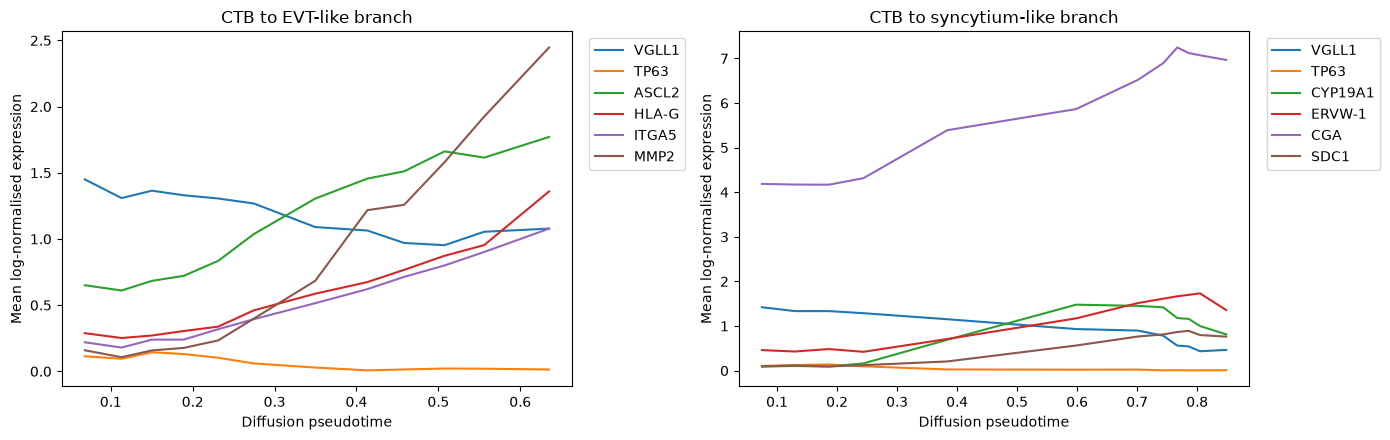

In [16]:
def branch_trend(ax, states, genes, title):
    """Mean expression along pseudotime for the cells of one branch (about equal numbers of cells per interval)."""
    cells = sub14.obs["cell_state_v2"].isin(states)                          # cells that belong to this branch
    genes = [g for g in genes if g in sub14.var_names]
    X = sub14[cells, genes].X
    X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
    df = pd.DataFrame(X, columns=genes, index=sub14.obs_names[cells])
    pt = hv14.obs.loc[df.index, "dpt_pseudotime"]
    bins = pd.qcut(pt, q=12, duplicates="drop")                              # 12 intervals with similar numbers of cells
    trend = df.groupby(bins, observed=True)[genes].mean()
    x = pt.groupby(bins, observed=True).median()
    for g in genes:
        ax.plot(x.to_numpy(), trend[g].to_numpy(), label=g)
    ax.set_title(title); ax.set_xlabel("Diffusion pseudotime"); ax.set_ylabel("Mean log-normalised expression")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
branch_trend(axes[0], ["CTB-like (bCTB)", "EVT-like (bEVT)"],
             ["VGLL1", "TP63", "ASCL2", "HLA-G", "ITGA5", "MMP2"], "CTB to EVT-like branch")
branch_trend(axes[1], ["CTB-like (bCTB)", "Primitive syncytium-like (bPrSyn)", "ST-like (bSTB)"],
             ["VGLL1", "TP63", "CYP19A1", "ERVW-1", "CGA", "SDC1"], "CTB to syncytium-like branch")
fig.tight_layout()
fig.savefig(fig_dir / "D14_troph_gene_trends.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
robustness(hv14, ctb["ctb_score"].nlargest(5).index)

10 PCs: Spearman rho = 0.993 | CTB-like (bCTB) 0.20 < EVT-like (bEVT) 0.55 < Primitive syncytium-like (bPrSyn) 0.69 < ST-like (bSTB) 0.80
20 PCs: Spearman rho = 0.997 | CTB-like (bCTB) 0.16 < EVT-like (bEVT) 0.46 < Primitive syncytium-like (bPrSyn) 0.62 < ST-like (bSTB) 0.75
2nd-best root: Spearman rho = 0.967 | CTB-like (bCTB) 0.25 < EVT-like (bEVT) 0.52 < Primitive syncytium-like (bPrSyn) 0.58 < ST-like (bSTB) 0.74
5th-best root: Spearman rho = 0.987 | CTB-like (bCTB) 0.17 < EVT-like (bEVT) 0.51 < Primitive syncytium-like (bPrSyn) 0.63 < ST-like (bSTB) 0.76


In [18]:
adata = sc.read_h5ad(proc_dir / "merged_annotated_v2.h5ad")
emb_states = ["Epiblast-like (bEPI, D14/D21)", "Primitive streak / emergent mesoderm-like",
              "Mesoderm-like (intermediate)", "Mesoderm-like (bAdMes/bExMes)",
              "Endoderm-like (bDE/bYSE)", "Amnion-like (bAME)"]          # embryonic-side states of D21
keep = ((adata.obs["sample"] == "D21") & (~adata.obs["exclude_default"])
        & adata.obs["cell_state_v2"].isin(emb_states))                    # D21 only (cluster 4 also holds D14 cells)
sub21 = adata[keep].copy()
sub21.obs["cell_state_v2"] = sub21.obs["cell_state_v2"].cat.remove_unused_categories()
print(sub21.shape)
print(sub21.obs["cell_state_v2"].value_counts())
del adata
gc.collect()

(3024, 36601)
cell_state_v2
Mesoderm-like (bAdMes/bExMes)                1590
Epiblast-like (bEPI, D14/D21)                 909
Endoderm-like (bDE/bYSE)                      217
Mesoderm-like (intermediate)                  139
Primitive streak / emergent mesoderm-like     108
Amnion-like (bAME)                             61
Name: count, dtype: int64


6379

C:\Users\ADMIN\miniconda3\envs\blastoid\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


root cell: GCAACATTCTTTCCGG-1_D21
cell_state_v2
Epiblast-like (bEPI, D14/D21)                0.075
Primitive streak / emergent mesoderm-like    0.477
Amnion-like (bAME)                           0.544
Endoderm-like (bDE/bYSE)                     0.585
Mesoderm-like (bAdMes/bExMes)                0.617
Mesoderm-like (intermediate)                 0.630
Name: dpt_pseudotime, dtype: float32


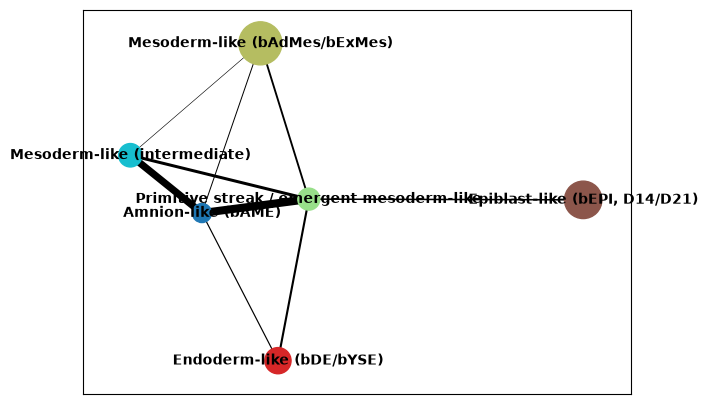

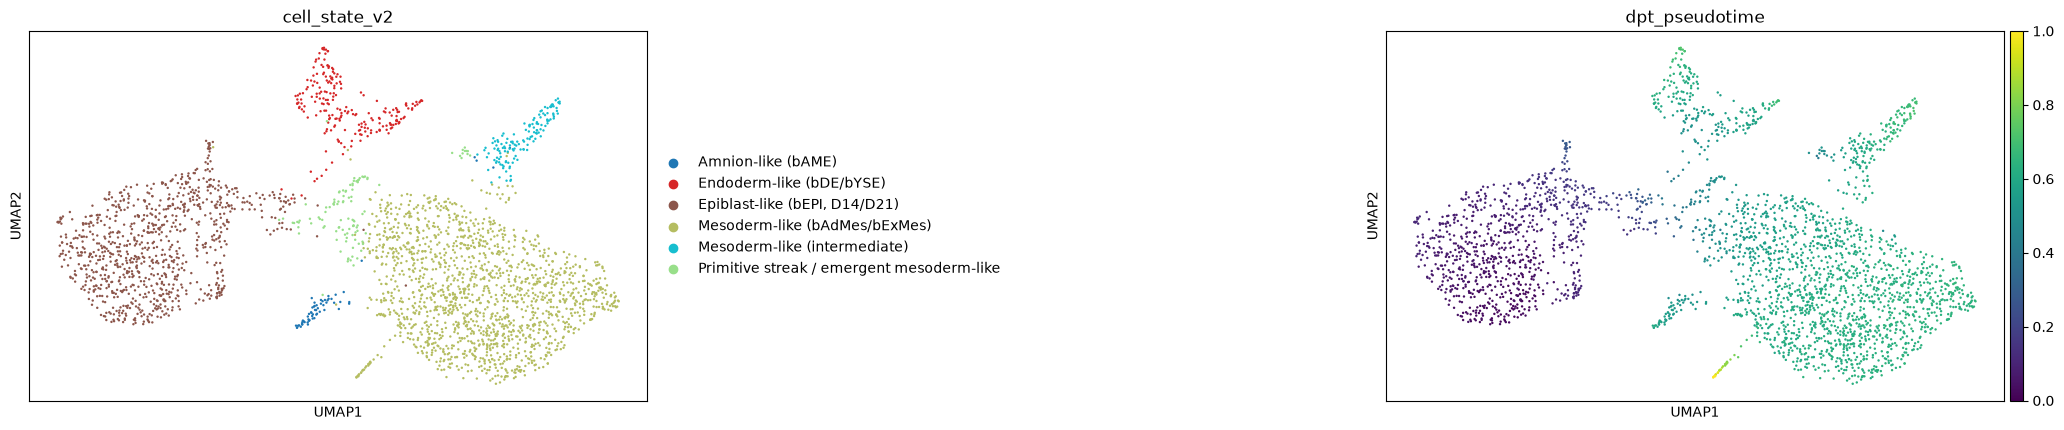

In [19]:
hv21 = embed_subset(sub21)                                                # HVGs, PCA (15 PCs), neighbours, UMAP on D21 embryonic cells

# Root: epiblast-like cell with the highest mean expression of epiblast genes reported for bEPI at D21
epi_genes = [g for g in ["POU5F1", "NANOG", "SOX2", "SFRP2"] if g in sub21.var_names]
sc.tl.score_genes(sub21, gene_list=epi_genes, score_name="epi_score")
hv21.obs["epi_score"] = sub21.obs["epi_score"].to_numpy()                 # same cell order in both objects
epi21 = hv21.obs[hv21.obs["cell_state_v2"] == "Epiblast-like (bEPI, D14/D21)"]
root21 = epi21["epi_score"].idxmax()
hv21.uns["iroot"] = int(np.flatnonzero(hv21.obs_names == root21)[0])
print("root cell:", root21)

sc.tl.diffmap(hv21)
sc.tl.dpt(hv21, n_dcs=10)
print(hv21.obs.groupby("cell_state_v2", observed=True)["dpt_pseudotime"].median().sort_values().round(3))

sc.tl.paga(hv21, groups="cell_state_v2")
sc.pl.paga(hv21, threshold=0.05, node_size_scale=2, show=False)
plt.gcf().savefig(fig_dir / "D21_embryonic_paga.png", dpi=200, bbox_inches="tight")
plt.show()

sc.pl.umap(hv21, color=["cell_state_v2", "dpt_pseudotime"], ncols=2, wspace=1.0, size=12, show=False)
plt.gcf().savefig(fig_dir / "D21_embryonic_pseudotime_umap.png", dpi=200, bbox_inches="tight")
plt.show()

hv21.obs[["cell_state_v2", "epi_score", "dpt_pseudotime"]].to_csv(result_dir / "D21_embryonic_pseudotime.csv")

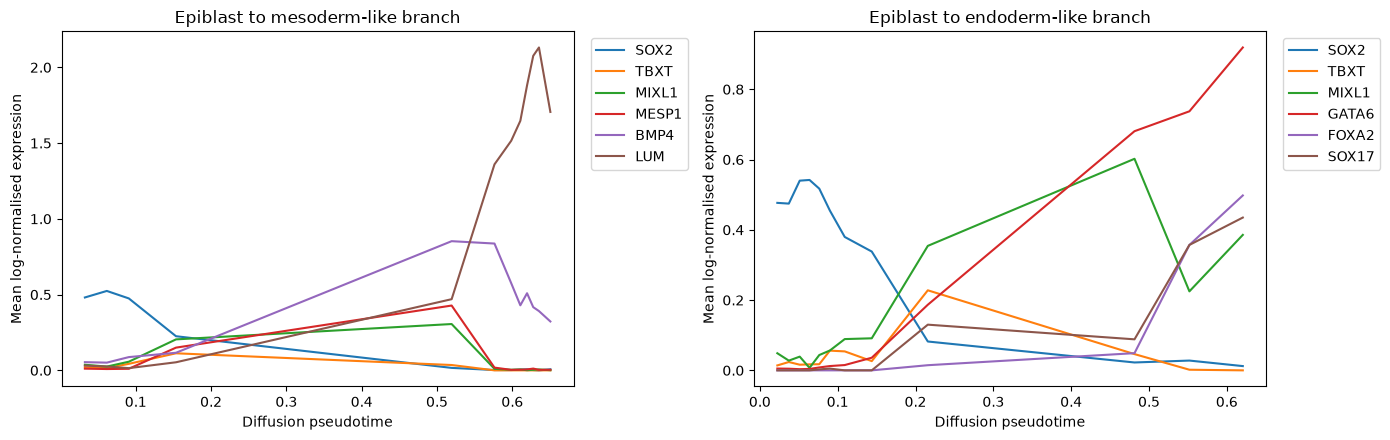

In [20]:
def branch_trend2(ax, sub, hv, states, genes, title, n_bins=12):
    """Mean expression along pseudotime for the cells of one branch (about equal numbers of cells per interval)."""
    cells = sub.obs["cell_state_v2"].isin(states)                           # cells belonging to this branch
    genes = [g for g in genes if g in sub.var_names]
    X = sub[cells, genes].X
    X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
    df = pd.DataFrame(X, columns=genes, index=sub.obs_names[cells])
    pt = hv.obs.loc[df.index, "dpt_pseudotime"]
    bins = pd.qcut(pt, q=n_bins, duplicates="drop")
    trend = df.groupby(bins, observed=True)[genes].mean()
    x = pt.groupby(bins, observed=True).median()
    for g in genes:
        ax.plot(x.to_numpy(), trend[g].to_numpy(), label=g)
    ax.set_title(title); ax.set_xlabel("Diffusion pseudotime"); ax.set_ylabel("Mean log-normalised expression")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
branch_trend2(axes[0], sub21, hv21,
              ["Epiblast-like (bEPI, D14/D21)", "Primitive streak / emergent mesoderm-like",
               "Mesoderm-like (intermediate)", "Mesoderm-like (bAdMes/bExMes)"],
              ["SOX2", "TBXT", "MIXL1", "MESP1", "BMP4", "LUM"], "Epiblast to mesoderm-like branch")
branch_trend2(axes[1], sub21, hv21,
              ["Epiblast-like (bEPI, D14/D21)", "Primitive streak / emergent mesoderm-like", "Endoderm-like (bDE/bYSE)"],
              ["SOX2", "TBXT", "MIXL1", "GATA6", "FOXA2", "SOX17"], "Epiblast to endoderm-like branch")
fig.tight_layout()
fig.savefig(fig_dir / "D21_embryonic_gene_trends.png", dpi=200, bbox_inches="tight")
plt.show()

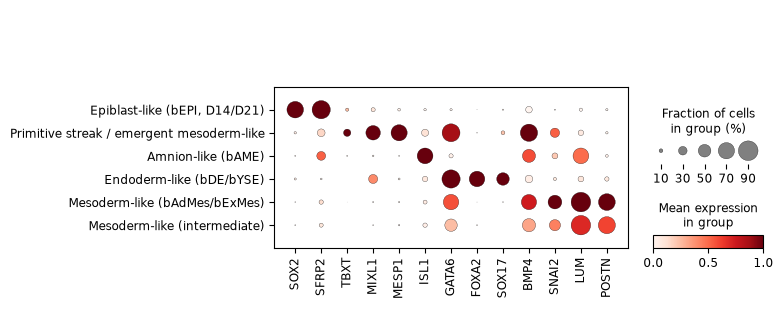

In [22]:
# Order the cell states from earliest to latest median pseudotime
order = hv21.obs.groupby("cell_state_v2", observed=True)["dpt_pseudotime"].median().sort_values().index.tolist()
genes = [g for g in ["SOX2", "SFRP2", "TBXT", "MIXL1", "MESP1", "ISL1", "GATA6", "FOXA2", "SOX17", "BMP4", "SNAI2", "LUM", "POSTN"]
         if g in sub21.var_names]                                      # keep genes present in our data
# Dot size = fraction of cells expressing the gene; colour = mean expression scaled per gene
sc.pl.dotplot(sub21, var_names=genes, groupby="cell_state_v2", categories_order=order, standard_scale="var", show=False)
plt.gcf().savefig(fig_dir / "D21_embryonic_state_dotplot.png", dpi=200, bbox_inches="tight")
plt.show()

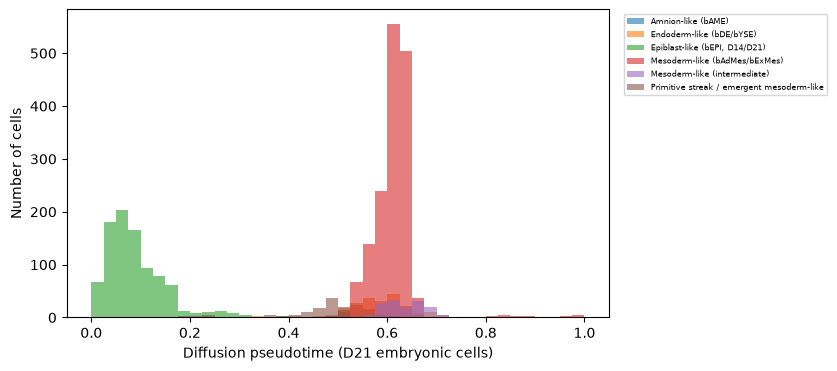

In [23]:
plt.figure(figsize=(7, 4))
for state, d in hv21.obs.groupby("cell_state_v2", observed=True):      # one histogram per cell state
    plt.hist(d["dpt_pseudotime"], bins=40, range=(0, 1), alpha=0.6, label=state)
plt.xlabel("Diffusion pseudotime (D21 embryonic cells)")
plt.ylabel("Number of cells")
plt.legend(fontsize=6, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig(fig_dir / "D21_embryonic_pseudotime_hist.png", dpi=200, bbox_inches="tight")
plt.show()

leiden_r05_sub13
13,0    239
13,1    133
13,2    139
13,3    239
13,4    273
13,5    285
13,6    288


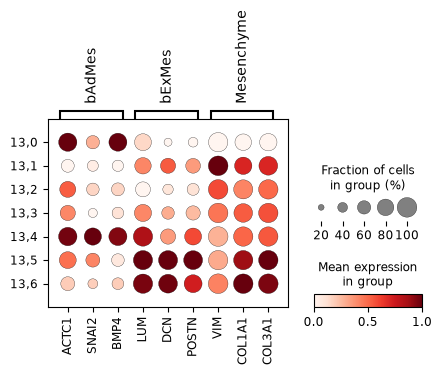

In [24]:
adata = sc.read_h5ad(proc_dir / "merged_annotated_v2.h5ad")             # includes the neighbours graph and leiden_r05 labels
key = "leiden_r05"
# Split only cluster 13 into smaller groups; the other clusters keep their labels
sc.tl.leiden(adata, resolution=0.5, restrict_to=(key, ["13"]), key_added="leiden_r05_sub13",
             flavor="igraph", n_iterations=2, directed=False, random_state=0)
n = adata.obs.loc[adata.obs[key] == "13", "leiden_r05_sub13"].value_counts()
print(n[n > 0].sort_index().to_string())                                 # sizes of the new sub-groups of cluster 13

sets13 = {                                                              # markers of the two mesoderm populations in the original study
    "bAdMes": ["ACTC1", "SNAI2", "BMP4"],
    "bExMes": ["LUM", "DCN", "POSTN"],
    "Mesenchyme": ["VIM", "COL1A1", "COL3A1"],
}
sets13 = {k: [g for g in v if g in adata.var_names] for k, v in sets13.items()}
sub13 = adata[adata.obs[key] == "13"].copy()                            # cluster 13 only
sub13.obs["grp"] = sub13.obs["leiden_r05_sub13"].astype(str).astype("category")
sc.pl.dotplot(sub13, var_names=sets13, groupby="grp", standard_scale="var", show=False)
plt.gcf().savefig(fig_dir / "dotplot_cluster13_subclusters.png", dpi=200, bbox_inches="tight")
plt.show()

In [25]:
# Map each sub-group of cluster 13 to a more specific label (CHECK against the dotplot and the sizes printed in Cell 16)
sub13_labels = {
    "13,0": "Advanced mesoderm-like (bAdMes)",
    "13,4": "Advanced mesoderm-like (bAdMes)",
    "13,5": "Extraembryonic mesoderm-like (bExMes)",
    "13,6": "Extraembryonic mesoderm-like (bExMes)",
    "13,1": "Mesenchyme-like (mixed)",
    "13,2": "Mesenchyme-like (mixed)",
    "13,3": "Mesenchyme-like (mixed)",
}
sub = adata.obs["leiden_r05_sub13"].astype(str)                       # sub-group label of each cell
in13 = adata.obs["leiden_r05"].astype(str).eq("13")                   # cells that belong to cluster 13
v3 = adata.obs["cell_state_v2"].astype(str)                           # start from the v2 labels
v3.loc[in13] = sub[in13].map(sub13_labels)                            # overwrite only the labels of cluster 13 cells
adata.obs["cell_state_v3"] = v3.astype("category")
print(int(adata.obs["cell_state_v3"].isna().sum()), "cells without a label (should be 0)")   # an unmapped sub-group such as 13,7 would show up here

print(pd.crosstab(adata.obs.loc[in13, "leiden_r05_sub13"], adata.obs.loc[in13, "cell_state_v3"]))   # sub-group -> label table

cols = ["sample", "leiden_r05", "leiden_r05_sub", "leiden_r05_sub13", "cell_state_v2", "cell_state_v3", "exclude_default"]
adata.obs[cols].to_csv(result_dir / "cell_state_v3_labels.csv")       # index = cell name (<barcode>_<sample>)

0 cells without a label (should be 0)
cell_state_v3     Advanced mesoderm-like (bAdMes)  \
leiden_r05_sub13                                    
13,0                                          239   
13,1                                            0   
13,2                                            0   
13,3                                            0   
13,4                                          273   
13,5                                            0   
13,6                                            0   

cell_state_v3     Extraembryonic mesoderm-like (bExMes)  \
leiden_r05_sub13                                          
13,0                                                  0   
13,1                                                  0   
13,2                                                  0   
13,3                                                  0   
13,4                                                  0   
13,5                                                285   
13,6        

(1942, 36601)
cell_state_v3
Epiblast-like (bEPI, D14/D21)                909
Advanced mesoderm-like (bAdMes)              508
Endoderm-like (bDE/bYSE)                     217
Mesoderm-like (intermediate)                 139
Primitive streak / emergent mesoderm-like    108
Amnion-like (bAME)                            61
Name: count, dtype: int64


C:\Users\ADMIN\miniconda3\envs\blastoid\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cell_state_v3
Epiblast-like (bEPI, D14/D21)                0.086
Primitive streak / emergent mesoderm-like    0.574
Amnion-like (bAME)                           0.631
Advanced mesoderm-like (bAdMes)              0.772
Endoderm-like (bDE/bYSE)                     0.774
Mesoderm-like (intermediate)                 0.817
Name: dpt_pseudotime, dtype: float32
cells with pseudotime > 0.8: 337 | {'Advanced mesoderm-like (bAdMes)': 199, 'Mesoderm-like (intermediate)': 86, 'Endoderm-like (bDE/bYSE)': 52, 'Amnion-like (bAME)': 0, 'Epiblast-like (bEPI, D14/D21)': 0, 'Primitive streak / emergent mesoderm-like': 0}


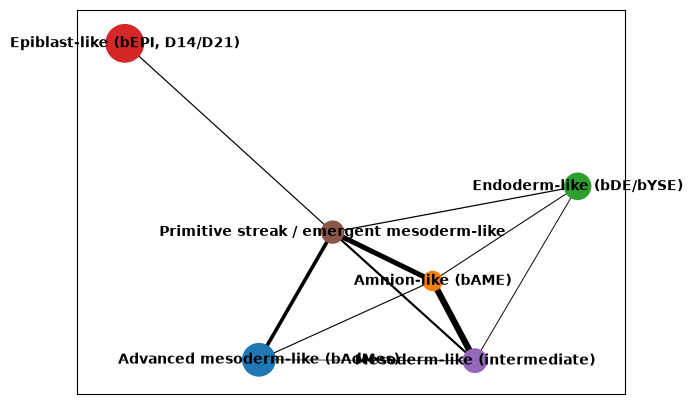

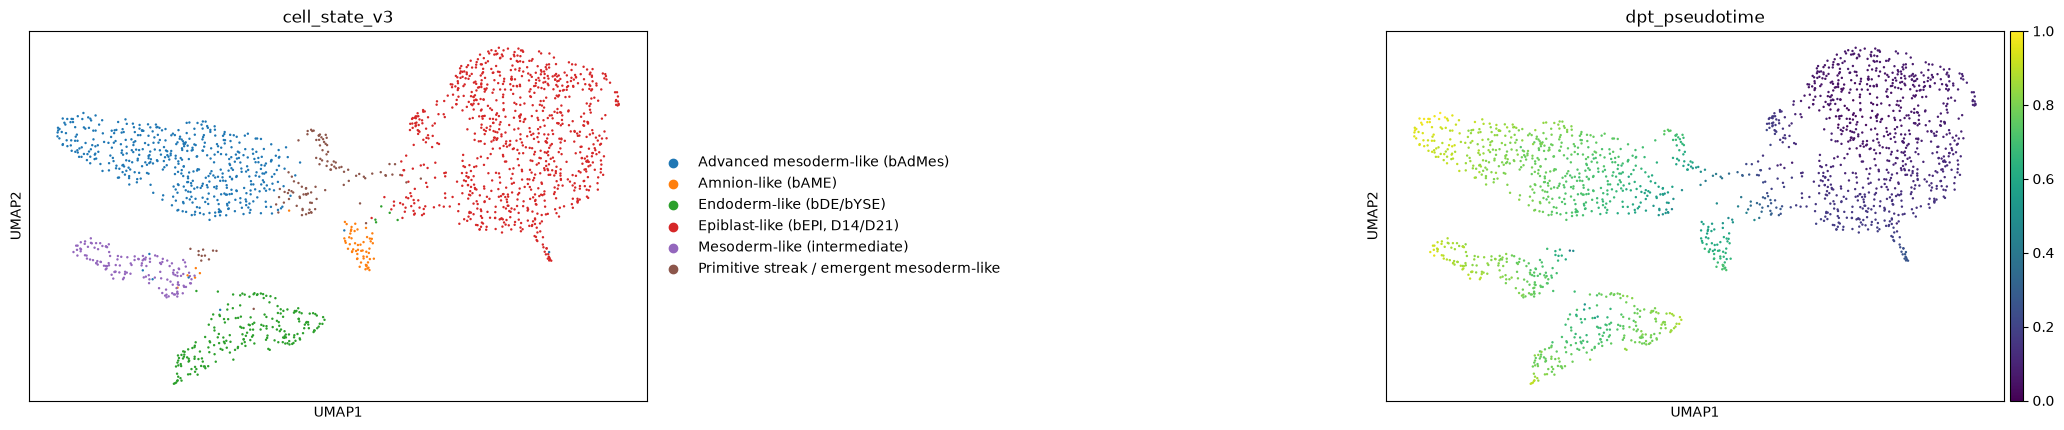

10 PCs: Spearman rho = 0.962 | Epiblast-like (bEPI, D14/D21) 0.14 < Primitive streak / emergent mesoderm-like 0.54 < Amnion-like (bAME) 0.68 < Endoderm-like (bDE/bYSE) 0.71 < Advanced mesoderm-like (bAdMes) 0.72 < Mesoderm-like (intermediate) 0.84
20 PCs: Spearman rho = 0.971 | Epiblast-like (bEPI, D14/D21) 0.08 < Primitive streak / emergent mesoderm-like 0.62 < Amnion-like (bAME) 0.70 < Advanced mesoderm-like (bAdMes) 0.80 < Endoderm-like (bDE/bYSE) 0.85 < Mesoderm-like (intermediate) 0.87
2nd-best root: Spearman rho = 0.872 | Epiblast-like (bEPI, D14/D21) 0.10 < Primitive streak / emergent mesoderm-like 0.55 < Amnion-like (bAME) 0.61 < Advanced mesoderm-like (bAdMes) 0.76 < Endoderm-like (bDE/bYSE) 0.76 < Mesoderm-like (intermediate) 0.80
5th-best root: Spearman rho = 0.869 | Epiblast-like (bEPI, D14/D21) 0.11 < Primitive streak / emergent mesoderm-like 0.56 < Amnion-like (bAME) 0.62 < Advanced mesoderm-like (bAdMes) 0.76 < Endoderm-like (bDE/bYSE) 0.76 < Mesoderm-like (intermediate)

In [26]:
emb3 = ["Epiblast-like (bEPI, D14/D21)", "Primitive streak / emergent mesoderm-like", "Mesoderm-like (intermediate)",
        "Advanced mesoderm-like (bAdMes)", "Endoderm-like (bDE/bYSE)", "Amnion-like (bAME)"]   # embryonic-side states of D21
keep = ((adata.obs["sample"] == "D21") & (~adata.obs["exclude_default"]) & adata.obs["cell_state_v3"].isin(emb3))
sub21b = adata[keep].copy()
sub21b.obs["cell_state_v3"] = sub21b.obs["cell_state_v3"].cat.remove_unused_categories()   # drop labels not present any more
print(sub21b.shape)
print(sub21b.obs["cell_state_v3"].value_counts())

hv21b = embed_subset(sub21b)                                            # HVGs, PCA (15 PCs), neighbours, UMAP on this subset

# Root: epiblast-like cell with the highest mean expression of the epiblast genes reported for D21
epi_genes = [g for g in ["POU5F1", "NANOG", "SOX2", "SFRP2"] if g in sub21b.var_names]
sc.tl.score_genes(sub21b, gene_list=epi_genes, score_name="epi_score")
hv21b.obs["epi_score"] = sub21b.obs["epi_score"].to_numpy()             # same cell order in both objects
epi21b = hv21b.obs[hv21b.obs["cell_state_v3"] == "Epiblast-like (bEPI, D14/D21)"]
root21b = epi21b["epi_score"].idxmax()
hv21b.uns["iroot"] = int(np.flatnonzero(hv21b.obs_names == root21b)[0])

sc.tl.diffmap(hv21b)
sc.tl.dpt(hv21b, n_dcs=10)
print(hv21b.obs.groupby("cell_state_v3", observed=True)["dpt_pseudotime"].median().sort_values().round(3))
late = hv21b.obs["dpt_pseudotime"] > 0.8                                # the thin tail of far-away cells seen on the UMAP
print("cells with pseudotime > 0.8:", int(late.sum()), "|", hv21b.obs.loc[late, "cell_state_v3"].value_counts().to_dict())

sc.tl.paga(hv21b, groups="cell_state_v3")
sc.pl.paga(hv21b, threshold=0.05, node_size_scale=2, show=False)
plt.gcf().savefig(fig_dir / "D21_embryonic_v3_paga.png", dpi=200, bbox_inches="tight")
plt.show()

sc.pl.umap(hv21b, color=["cell_state_v3", "dpt_pseudotime"], ncols=2, wspace=1.0, size=12, show=False)
plt.gcf().savefig(fig_dir / "D21_embryonic_v3_pseudotime_umap.png", dpi=200, bbox_inches="tight")
plt.show()

hv21b.obs[["cell_state_v3", "epi_score", "dpt_pseudotime"]].to_csv(result_dir / "D21_embryonic_v3_pseudotime.csv")
robustness(hv21b, epi21b["epi_score"].nlargest(5).index, label_col="cell_state_v3")   # alternative PCs and roots

sample                                                D7   D14   D21
cell_state_v3                                                       
Advanced mesoderm-like (bAdMes)                      0.0   0.1   9.3
Amnion-like (bAME)                                   0.0   0.1   1.1
CTB-like (bCTB)                                      0.0  21.2  14.1
EVT-like (bEVT)                                      0.0  24.2  22.5
Endoderm-like (bDE/bYSE)                             0.0   0.5   4.0
Epiblast-like (TE-primed, D7)                       10.2   0.0   0.0
Epiblast-like (bEPI, D14/D21)                        0.0  10.9  16.7
Epiblast-like (bEPI, D7)                            41.6   0.0   0.0
Extraembryonic mesoderm-like (bExMes)                0.0   0.0  10.5
Mesenchyme-like (mixed)                              0.0   0.1   9.3
Mesoderm-like (intermediate)                         0.0   0.1   2.5
Polar TE-like (bPolarTE)                             2.2   0.0   0.0
Primitive endoderm-like (bPE)     

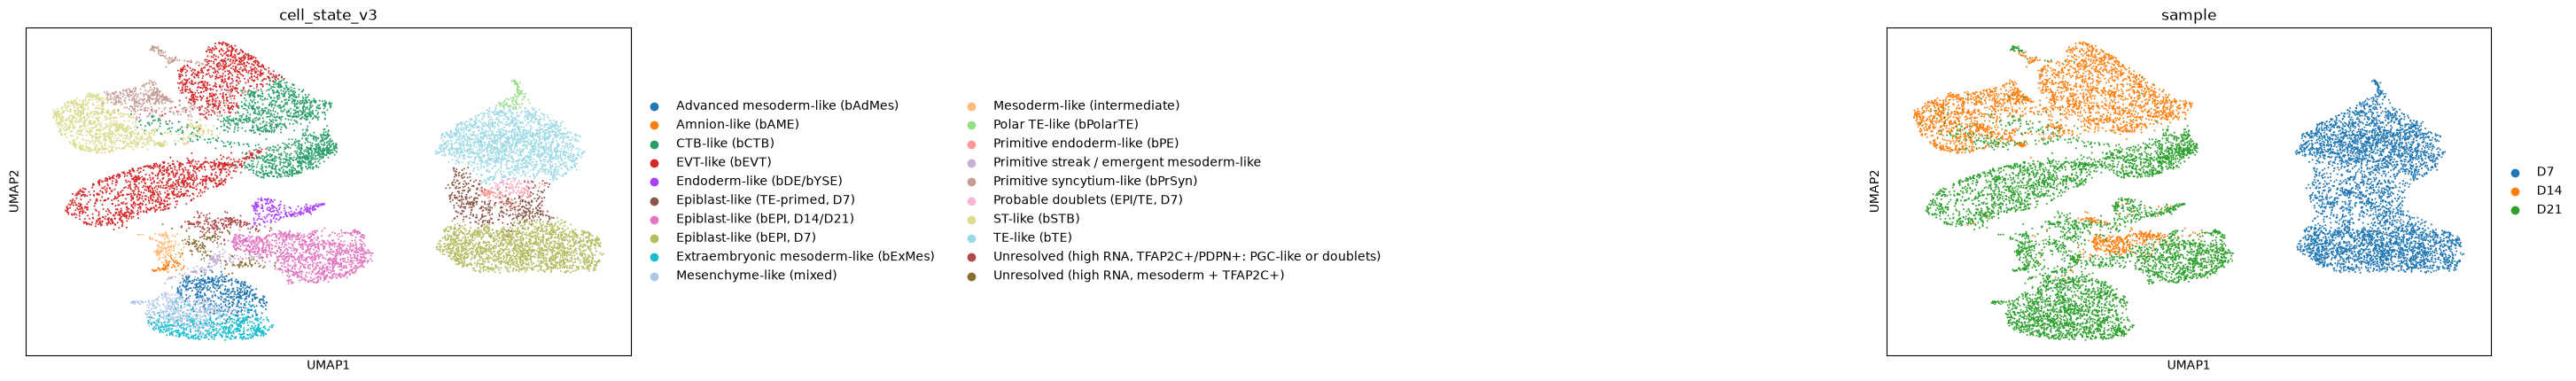

In [27]:
# Percentage of each sample made up of each v3 cell state (descriptive only: one sample per timepoint)
comp3 = (pd.crosstab(adata.obs["cell_state_v3"], adata.obs["sample"], normalize="columns") * 100).round(1)
comp3.to_csv(result_dir / "cell_state_v3_composition.csv")
print(comp3)

# Overview UMAP of all samples, coloured by the final cell states and by sample
sc.pl.umap(adata, color=["cell_state_v3", "sample"], ncols=2, wspace=1.8, size=8, show=False)
plt.gcf().savefig(fig_dir / "umap_cell_states_v3.png", dpi=200, bbox_inches="tight")
plt.show()

0 cells without a lineage (should be 0)
lineage
Trophoblast-like                             6923
Epiblast-like                                3618
Extraembryonic mesoderm / mesenchyme-like    1084
Primitive streak / mesoderm-like              780
Flagged / unresolved                          422
Endoderm-like                                 348
Amnion-like                                    65
Name: count, dtype: int64


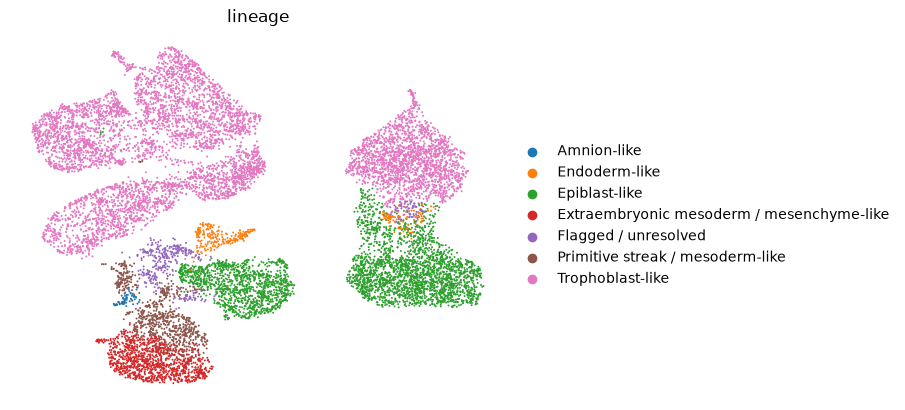

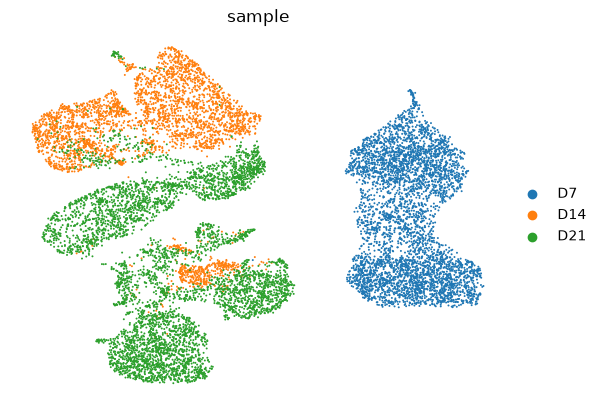

In [28]:
# Broad lineages for an overview figure; the detailed labels stay in cell_state_v3
lineage_map = {
    "Epiblast-like (bEPI, D7)": "Epiblast-like",
    "Epiblast-like (TE-primed, D7)": "Epiblast-like",
    "Epiblast-like (bEPI, D14/D21)": "Epiblast-like",
    "TE-like (bTE)": "Trophoblast-like",
    "Polar TE-like (bPolarTE)": "Trophoblast-like",
    "CTB-like (bCTB)": "Trophoblast-like",
    "EVT-like (bEVT)": "Trophoblast-like",
    "ST-like (bSTB)": "Trophoblast-like",
    "Primitive syncytium-like (bPrSyn)": "Trophoblast-like",
    "Primitive endoderm-like (bPE)": "Endoderm-like",
    "Endoderm-like (bDE/bYSE)": "Endoderm-like",
    "Primitive streak / emergent mesoderm-like": "Primitive streak / mesoderm-like",
    "Mesoderm-like (intermediate)": "Primitive streak / mesoderm-like",
    "Advanced mesoderm-like (bAdMes)": "Primitive streak / mesoderm-like",
    "Extraembryonic mesoderm-like (bExMes)": "Extraembryonic mesoderm / mesenchyme-like",
    "Mesenchyme-like (mixed)": "Extraembryonic mesoderm / mesenchyme-like",
    "Amnion-like (bAME)": "Amnion-like",
    "Probable doublets (EPI/TE, D7)": "Flagged / unresolved",
    "Unresolved (high RNA, TFAP2C+/PDPN+: PGC-like or doublets)": "Flagged / unresolved",
    "Unresolved (high RNA, mesoderm + TFAP2C+)": "Flagged / unresolved",
}
adata.obs["lineage"] = adata.obs["cell_state_v3"].astype(str).map(lineage_map).astype("category")
print(int(adata.obs["lineage"].isna().sum()), "cells without a lineage (should be 0)")   # a label missing from the dictionary would show up here
print(adata.obs["lineage"].value_counts())

# One figure per colouring, legend on the right, no axis frame: easier to read in a README
sc.pl.umap(adata, color="lineage", size=8, legend_loc="right margin", frameon=False, show=False)
plt.gcf().savefig(fig_dir / "umap_lineages_overview.png", dpi=200, bbox_inches="tight")
plt.show()
sc.pl.umap(adata, color="sample", size=8, legend_loc="right margin", frameon=False, show=False)
plt.gcf().savefig(fig_dir / "umap_by_sample.png", dpi=200, bbox_inches="tight")
plt.show()